# Un assistant qui répond aux questions sur les rapports ITIE, en citant la page (RAG)

**La question :** peut-on poser une question en français sur les rapports ITIE Guinée (« combien la SMB a-t-elle payé à l'État en 2023 ? ») et obtenir le bon chiffre, avec la page où le vérifier ?

**Le problème :** un grand modèle de langage comme Gemini ne connaît pas ces rapports. Sans aide, il invente un chiffre ou dit qu'il ne sait pas. Et lui envoyer les 800 pages des deux rapports à chaque question serait lent et coûteux.

**La méthode, le RAG** (*Retrieval-Augmented Generation*, génération augmentée par la recherche) :
1. **Recherche :** les rapports sont découpés en passages. Pour chaque question, un index TF-IDF (le même principe que le classifieur du notebook 07b) retrouve les 4 passages les plus proches. Cette partie tourne sur le PC, sans Gemini.
2. **Génération :** Gemini reçoit la question et **seulement ces 4 passages**, avec une consigne stricte : répondre uniquement à partir des extraits, recopier les chiffres, citer la page, et dire « Je ne sais pas » si la réponse n'y est pas.

**Le test :** 10 questions dont la réponse exacte est connue (`data/rag_questions.csv`), dont une question piège sans réponse dans les rapports.

Le code est dans `src/rag_itie.py`. Les réponses de Gemini ont été obtenues avec `src/evaluer_rag.py` (fichier `data/rag_reponses.csv`). L'assistant s'utilise aussi dans une page web : `py -3.13 -m streamlit run src/app_assistant.py`.

In [1]:
import sys
sys.path.append("..")

import pandas as pd

from src.rag_itie import Recherche, decouper_passages, fiches_paiements, reponse_juste
from src.graphiques import graphique_rag

pd.set_option("display.max_colwidth", 120)

## 1. Découper les rapports en passages

In [2]:
pages = pd.read_csv("../data/itie/pages_etiquetees.csv")
passages_texte = decouper_passages(pages)
print(f"{len(pages)} pages -> {len(passages_texte)} passages d'environ 1 200 caractères")
passages_texte.head(3)

370 pages -> 1062 passages d'environ 1 200 caractères


,annee,page,section,passage
0,2022,10,1.2,1 APERÇU DE L’ITIE EN GUINEE\n1.1 Historique\nL’industrie extractive en Guinée repose principalement sur l’exploitat...
1,2022,10,1.2,8 Exercice 2012 Décembre 2013\n9 Exercice 2013 Décembre 2015\n10 Exercice 2014 Décembre 2016\n11 Exercice 2015 Févri...
2,2022,11,1.3,1.3 Périmètre des travaux\nLes travaux de l’Administrateur Indépendant ont consisté principalement à :\ni. collecter...


**Pourquoi des passages et pas des pages entières ?** Une page mélange souvent plusieurs sujets. Un passage plus court parle d'un seul sujet : la recherche est plus précise, et Gemini reçoit moins de texte inutile. La découpe se fait entre deux lignes, pour ne jamais couper une ligne de tableau en deux.

## 2. Première version : la recherche dans le texte seul

In [3]:
questions = pd.read_csv("../data/rag_questions.csv", dtype=str).fillna("")
avec_reponse = questions[questions["reponse_attendue"] != "je ne sais pas"]


def tester_recherche(passages, nb=4):
    """Pour chaque question, vrai si un des nb passages trouvés contient la réponse attendue."""
    recherche = Recherche(passages)
    lignes = []
    for q in avec_reponse.itertuples():
        trouves = recherche.chercher(q.question, nb=nb)
        lignes.append({
            "question": q.question,
            "pages trouvées": ", ".join(str(p) for p in trouves["page"]),
            "page attendue": q.page_source,
            "bon passage trouvé": any(reponse_juste(t, q.reponse_attendue) for t in trouves["passage"]),
        })
    return pd.DataFrame(lignes)


version_1 = tester_recherche(passages_texte)
print(f"Bon passage trouvé : {version_1['bon passage trouvé'].sum()} questions sur {len(version_1)}")
version_1

Bon passage trouvé : 6 questions sur 9


,question,pages trouvées,page attendue,bon passage trouvé
0,Combien la Société Minière de Boké (SMB) a-t-elle déclaré avoir payé à l'État en 2023 ?,"91, 91, 80, 71",151,False
1,Combien l'État déclare-t-il avoir reçu de la Compagnie des Bauxites de Guinée (CBG) en 2023 ?,"156, 71, 158, 75",151,False
2,Quel est l'écart entre les montants déclarés par la SMB et par l'État en 2023 ?,"17, 170, 169, 78",151,False
3,Combien de sociétés minières ont été incluses dans le périmètre de réconciliation en 2022 ?,"130, 16, 144, 161",16,True
4,Combien de sociétés minières ont été incluses dans le périmètre de réconciliation en 2023 ?,"138, 14, 14, 138",14,True
5,Quel taux de change USD/GNF a été utilisé pour convertir les montants du rapport 2022 ?,"94, 77, 11, 22",11,True
6,De combien de pourcents les revenus du secteur extractif ont-ils diminué en 2023 ?,"13, 50, 163, 141",13,True
7,Quelle part des revenus du secteur extractif provient des mines et carrières en 2023 ?,"13, 164, 163, 164",13,True
8,Quel montant la société GAC a-t-elle déclaré après ajustements en 2022 ?,"131, 156, 164, 162",156,True


**Constat :** la recherche trouve le bon passage pour 6 questions sur 9. Elle rate les **trois questions sur les montants par société** (SMB, CBG), qui se trouvent toutes dans le tableau de la page 151.

**Pourquoi ?** Dans le texte du PDF, une ligne de tableau n'est qu'une suite de chiffres :

In [4]:
tableau = passages_texte[(passages_texte["annee"] == 2023) & (passages_texte["page"] == 151)]
print(tableau["passage"].iloc[0][:700])

6.1.1 Rapprochements des flux de paiements par société
Les rapprochements des flux de paiements par société se détaillent comme suit :
Tableau 70 : Rapprochement des flux de paiement en numéraire par société extractive (pour les sociétés retenues dans le périmètre de rapprochement)
EN GNF
Déclarations initialement reçues Montants après ajustements
No Société Différence
Société extractive Gouvernement Société extractive Gouvernement Différence
(c) =
(a) (b) (g) = (a+d) (h) = (b+e) (i) = (g-h)
(a - b)
1 SOCIETE MINIERE DE BOKE SA 3 291 879 786 828 1 831 515 081 078 1 460 364 705 750 3 291 879 786 828 1 831 515 081 078 1 460 364 705 750
2 COMPAGNIE DES BAUXITES DE GUINEE C.B.G 955 845 476 077 9


Les mots de la question (« payé », « État », « SMB ») n'y figurent pas : le tableau dit « Gouvernement » et « SOCIETE MINIERE DE BOKE SA », sans le sigle. Pour TF-IDF, ce passage ne ressemble pas à la question.

## 3. Deuxième version : ajouter les tableaux extraits à l'étape 7

In [5]:
paiements = pd.read_csv("../data/itie_paiements_par_societe.csv")
societes = pd.read_csv("../data/itie_societes.csv")
fiches = fiches_paiements(paiements, societes)
print(f"{len(fiches)} fiches (une par société et par année). Exemple :\n")
print(fiches["passage"].iloc[13])

31 fiches (une par société et par année). Exemple :

Rapport ITIE 2023, tableau de rapprochement des paiements par société. Société : SOCIETE MINIERE DE BOKE SA (SMB). Montant que la société déclare avoir payé à l'État : 3 291 879 786 828 GNF. Montant que l'État (gouvernement) déclare avoir reçu de la société : 1 831 515 081 078 GNF. Écart entre la société et l'État : 1 460 364 705 750 GNF. Après ajustements : la société déclare 3 291 879 786 828 GNF, l'État déclare 1 831 515 081 078 GNF.


**L'idée :** au notebook 07, le tableau des paiements a déjà été extrait proprement avec `pdfplumber`. Chaque ligne est ici réécrite **en phrase**, avec le sigle de la société (`data/itie_societes.csv`). Ces phrases sont ajoutées aux passages, avec la page du tableau comme source.

C'est une technique courante en entreprise : un RAG ne cherche pas seulement dans du texte, il combine le texte et les **données structurées** (tables, bases de données).

In [6]:
passages = pd.concat([passages_texte, fiches])
version_2 = tester_recherche(passages)
print(f"Bon passage trouvé : {version_2['bon passage trouvé'].sum()} questions sur {len(version_2)}")
version_2

Bon passage trouvé : 9 questions sur 9


,question,pages trouvées,page attendue,bon passage trouvé
0,Combien la Société Minière de Boké (SMB) a-t-elle déclaré avoir payé à l'État en 2023 ?,"151, 151, 151, 151",151,True
1,Combien l'État déclare-t-il avoir reçu de la Compagnie des Bauxites de Guinée (CBG) en 2023 ?,"151, 151, 151, 151",151,True
2,Quel est l'écart entre les montants déclarés par la SMB et par l'État en 2023 ?,"151, 17, 170, 151",151,True
3,Combien de sociétés minières ont été incluses dans le périmètre de réconciliation en 2022 ?,"130, 16, 144, 161",16,True
4,Combien de sociétés minières ont été incluses dans le périmètre de réconciliation en 2023 ?,"138, 14, 14, 138",14,True
5,Quel taux de change USD/GNF a été utilisé pour convertir les montants du rapport 2022 ?,"94, 77, 11, 22",11,True
6,De combien de pourcents les revenus du secteur extractif ont-ils diminué en 2023 ?,"13, 50, 163, 141",13,True
7,Quelle part des revenus du secteur extractif provient des mines et carrières en 2023 ?,"13, 164, 163, 164",13,True
8,Quel montant la société GAC a-t-elle déclaré après ajustements en 2022 ?,"156, 156, 156, 156",156,True


**Constat :** avec les fiches, la recherche trouve le bon passage pour les **9 questions sur 9**.

## 4. Comparaison : quelle taille de passage ?

Pour chaque taille, on regarde à quel **rang** arrive le premier passage qui contient la bonne réponse (1 = en tête). Seuls les 4 premiers sont envoyés à Gemini : un rang supérieur à 4 est donc un échec.

In [7]:
def rangs(passages):
    """Rang du premier passage qui contient la bonne réponse, pour chaque question."""
    recherche = Recherche(passages)
    resultat = []
    for q in avec_reponse.itertuples():
        trouves = recherche.chercher(q.question, nb=len(passages))
        justes = [i for i, t in enumerate(trouves["passage"], start=1) if reponse_juste(t, q.reponse_attendue)]
        resultat.append(justes[0] if justes else None)
    return resultat


comparaison = pd.DataFrame({
    f"passages de {taille} car." if taille else "pages entières": rangs(pd.concat([decouper_passages(pages, taille or 99999), fiches]))
    for taille in [600, 1200, 2500, None]
}, index=[q[:60] for q in avec_reponse["question"]])
comparaison.loc["questions réussies (rang ≤ 4)"] = (comparaison <= 4).sum()
comparaison

,passages de 600 car.,passages de 1200 car.,passages de 2500 car.,pages entières
Combien la Société Minière de Boké (SMB) a-t-elle déclaré av,1,1,1,1
Combien l'État déclare-t-il avoir reçu de la Compagnie des B,1,1,1,1
Quel est l'écart entre les montants déclarés par la SMB et p,3,1,1,1
Combien de sociétés minières ont été incluses dans le périmè,1,1,1,1
Combien de sociétés minières ont été incluses dans le périmè,1,1,1,1
Quel taux de change USD/GNF a été utilisé pour convertir les,3,3,3,3
De combien de pourcents les revenus du secteur extractif ont,3,1,2,1
Quelle part des revenus du secteur extractif provient des mi,1,1,1,1
Quel montant la société GAC a-t-elle déclaré après ajustemen,1,1,1,1
questions réussies (rang ≤ 4),9,9,9,9


**Constat :**
- Avec les fiches, toutes les tailles réussissent les 9 questions : sur ce petit test, la taille compte moins que l'ajout des tableaux.
- Les passages de **600 caractères** placent trois bonnes réponses au 3e rang : ils coupent les phrases, et le contexte se perd.
- Les passages de **1 200 caractères** et les pages entières font aussi bien (presque tout au 1er rang). Mais une page entière fait environ 2 800 caractères : envoyer 4 pages à Gemini, c'est plus de deux fois plus de texte à lire pour le même résultat.

**1 200 caractères** est donc le meilleur compromis : la même précision, avec des extraits courts. C'est la taille retenue.

## 5. Les réponses de Gemini

In [8]:
reponses = pd.read_csv("../data/rag_reponses.csv")
print(f"Réponses justes : {reponses['juste'].sum()} sur {len(reponses)}")
print(f"Temps de réponse médian : {reponses['secondes'].median():.0f} s")
reponses[["question", "reponse_gemini", "juste"]]

Réponses justes : 10 sur 10
Temps de réponse médian : 13 s


,question,reponse_gemini,juste
0,Combien la Société Minière de Boké (SMB) a-t-elle déclaré avoir payé à l'État en 2023 ?,"En 2023, la Société Minière de Boké SA (SMB) a déclaré avoir payé 3 291 879 786 828 GNF à l'État. (rapport 2023, pag...",True
1,Combien l'État déclare-t-il avoir reçu de la Compagnie des Bauxites de Guinée (CBG) en 2023 ?,"L'État déclare avoir reçu 988 229 814 450 GNF de la Compagnie des Bauxites de Guinée (CBG) en 2023. (rapport 2023, p...",True
2,Quel est l'écart entre les montants déclarés par la SMB et par l'État en 2023 ?,L'écart entre le montant déclaré par la SOCIETE MINIERE DE BOKE SA (SMB) et le montant déclaré par l'État en 2023 es...,True
3,Combien de sociétés minières ont été incluses dans le périmètre de réconciliation en 2022 ?,"Au total, 13 sociétés du secteur des mines et carrières (ou Treize (13) sociétés du secteur minier) ont été incluses...",True
4,Combien de sociétés minières ont été incluses dans le périmètre de réconciliation en 2023 ?,"Au total, 18 sociétés (ou dix-huit (18) sociétés) du secteur des mines et carrières ont été incluses dans le périmèt...",True
5,Quel taux de change USD/GNF a été utilisé pour convertir les montants du rapport 2022 ?,"Le taux de change USD/GNF utilisé pour convertir les montants en dollars américains est de 8 553,2812 (rapport 2022,...",True
6,De combien de pourcents les revenus du secteur extractif ont-ils diminué en 2023 ?,"En 2023, les revenus du secteur extractif ont diminué de 8,76 % par rapport à 2022. (rapport 2023, page 13)",True
7,Quelle part des revenus du secteur extractif provient des mines et carrières en 2023 ?,"En 2023, le secteur des mines et carrières représente 89,41 % du total des revenus du secteur extractif (rapport 202...",True
8,Quel montant la société GAC a-t-elle déclaré après ajustements en 2022 ?,"Après ajustements, la société GUINEA ALUMINA CORPORATION (GAC) SA (GAC) a déclaré 478 803 048 967 GNF. (rapport 2022...",True
9,Quel est le prix du kilo d'or au marché de Conakry aujourd'hui ?,Je ne sais pas,True


**Constat :**
- **10 réponses justes sur 10.** Chaque chiffre est recopié exactement, avec la bonne page.
- **La question piège** (le prix de l'or à Conakry aujourd'hui) reçoit la réponse « Je ne sais pas » : l'assistant n'invente pas quand l'information n'est pas dans les rapports.
- Gemini ajoute parfois un contexte utile qui vient des extraits, par exemple : 13 sociétés en 2022, soit 10 retenues selon le seuil de matérialité et 3 ajoutées de façon permanente.

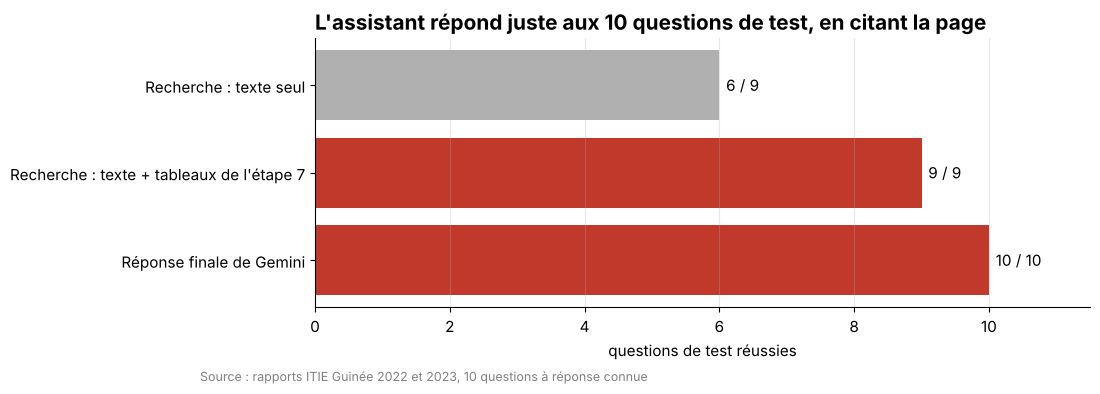

In [9]:
resultats = pd.DataFrame({
    "justes": [version_1["bon passage trouvé"].sum(), version_2["bon passage trouvé"].sum(), reponses["juste"].sum()],
    "total": [len(version_1), len(version_2), len(reponses)],
}, index=["Recherche : texte seul", "Recherche : texte + tableaux de l'étape 7", "Réponse finale de Gemini"])
graphique_rag(resultats, "L'assistant répond juste aux 10 questions de test, en citant la page")

## 6. Comparaison avec le notebook 07c

Au notebook 07c, Gemini devait classer des pages **sans aide** : 50 % de bonnes réponses. Ici, il reçoit les bons extraits et une consigne précise : 100 %. La différence ne vient pas du modèle, c'est le même : elle vient de **ce qu'on lui donne à lire**. C'est tout l'intérêt du RAG : le travail de recherche, fait par un modèle simple sur le PC, rend le grand modèle fiable.

## Conclusions

1. **L'assistant répond juste à 10 questions sur 10**, avec le chiffre exact et la page du rapport, et dit « Je ne sais pas » quand il ne sait pas.
2. **La recherche est la clé :** la première version ratait les montants par société. En ajoutant le tableau extrait à l'étape 7, réécrit en phrases, elle les trouve tous.
3. **Une question = un seul appel à Gemini**, avec 4 courts extraits : c'est rapide, peu coûteux, et le quota gratuit suffit.
4. **Chaque réponse est vérifiable :** la page est citée, et l'appli Streamlit affiche les extraits utilisés.

## Limites

- **10 questions seulement**, écrites en connaissant les rapports. Des utilisateurs réels poseraient des questions plus variées, avec d'autres mots.
- **TF-IDF cherche des mots, pas un sens :** une question avec des synonymes absents des rapports (« redevances » au lieu de « taxes ») peut rater le bon passage. Une recherche par *embeddings* (vecteurs de sens) serait l'étape suivante.
- Les fiches ne couvrent qu'un tableau : les autres tableaux des rapports (production, exportations) restent difficiles à retrouver.
- Les pages scannées (images) n'ont pas de texte et restent invisibles pour l'assistant.